# Graph 5 Vertex

## Bagian A — Persiapan dan pembuatan graph

### Import seluruh library

Cell pertama digunakan untuk mengimpor semua library yang dibutuhkan. Saya menambahkan NumPy dan Pandas agar hasil perhitungan dapat disajikan dalam bentuk tabel dan matriks yang lebih rapi.

In [33]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from collections import Counter

# Mengatur tampilan tabel Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 4)

# Mengatur ukuran font dan tampilan grafik
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10

print("Semua library berhasil diimport!")
print("Versi NetworkX:", nx.__version__)
print("Versi Pandas:", pd.__version__)


Semua library berhasil diimport!
Versi NetworkX: 3.7
Versi Pandas: 2.2.3


### Menentukan vertex dan edge

Pada cell ini kita menentukan lima vertex, yaitu A, B, C, D, dan E.Kemudian menentukan enam edge sesuai dengan notebook asli.

Edge yang sama digunakan untuk membuat dua jenis graph:
- Graph tidak berarah (Graph).
- Graph berarah (DiGraph).

Perbedaannya terletak pada arah hubungan antarvertex.

In [34]:
# Menentukan vertex
vertices = ['A', 'B', 'C', 'D', 'E']

# Menentukan edge
edges = [
    ('A', 'B'),
    ('A', 'C'),
    ('B', 'C'),
    ('B', 'D'),
    ('C', 'D'),
    ('D', 'E')
]

# Menampilkan daftar vertex
print("DAFTAR VERTEX")
print(vertices)

# Menampilkan daftar edge
print("\nDAFTAR EDGE")
for i, edge in enumerate(edges, start=1):
    print(f"{i}. {edge[0]} - {edge[1]}")

print("\nJumlah Vertex:", len(vertices))
print("Jumlah Edge:", len(edges))


DAFTAR VERTEX
['A', 'B', 'C', 'D', 'E']

DAFTAR EDGE
1. A - B
2. A - C
3. B - C
4. B - D
5. C - D
6. D - E

Jumlah Vertex: 5
Jumlah Edge: 6


### Membuat graph berarah dan tidak berarah

Cell ini digunakan untuk membentuk kedua graph menggunakan NetworkX.Pada graph tidak berarah, hubungan A-B berarti A terhubung dengan B dan B juga terhubung dengan A.Sedangkan pada graph berarah, hubungan A menuju B tidak otomatis berarti B menuju A.

In [35]:
# Membuat graph tidak berarah
G1 = nx.Graph()

# Membuat graph berarah
G2 = nx.DiGraph()

# Menambahkan vertex
G1.add_nodes_from(vertices)
G2.add_nodes_from(vertices)

# Menambahkan edge
G1.add_edges_from(edges)
G2.add_edges_from(edges)

# Menampilkan informasi graph
print("GRAPH TIDAK BERARAH")
print("Vertex:", list(G1.nodes()))
print("Edge:", list(G1.edges()))
print("Jumlah Vertex:", G1.number_of_nodes())
print("Jumlah Edge:", G1.number_of_edges())

print("\nGRAPH BERARAH")
print("Vertex:", list(G2.nodes()))
print("Edge:", list(G2.edges()))
print("Jumlah Vertex:", G2.number_of_nodes())
print("Jumlah Edge:", G2.number_of_edges())

# Memeriksa jenis graph
print("\nJenis G1:", type(G1).__name__)
print("Jenis G2:", type(G2).__name__)


GRAPH TIDAK BERARAH
Vertex: ['A', 'B', 'C', 'D', 'E']
Edge: [('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'D'), ('D', 'E')]
Jumlah Vertex: 5
Jumlah Edge: 6

GRAPH BERARAH
Vertex: ['A', 'B', 'C', 'D', 'E']
Edge: [('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'D'), ('D', 'E')]
Jumlah Vertex: 5
Jumlah Edge: 6

Jenis G1: Graph
Jenis G2: DiGraph


### Memeriksa keterhubungan graph

Beberapa pemeriksaan yang dilakukan:
- is_connected() untuk graph tidak berarah.
- is_weakly_connected() untuk graph berarah.
- is_strongly_connected() untuk graph berarah.
- Menghitung jumlah komponen graph.

In [36]:
print("PEMERIKSAAN GRAPH TIDAK BERARAH")
print("--------------------------------")

print("Apakah graph terhubung?",
      nx.is_connected(G1))

print("Jumlah connected components:",
      nx.number_connected_components(G1))

print("Connected components:",
      list(nx.connected_components(G1)))


print("\nPEMERIKSAAN GRAPH BERARAH")
print("--------------------------------")

print("Apakah weakly connected?",
      nx.is_weakly_connected(G2))

print("Apakah strongly connected?",
      nx.is_strongly_connected(G2))

print("Jumlah weakly connected components:",
      nx.number_weakly_connected_components(G2))

print("Jumlah strongly connected components:",
      nx.number_strongly_connected_components(G2))

print("\nWeakly connected components:")
print(list(nx.weakly_connected_components(G2)))

print("\nStrongly connected components:")
print(list(nx.strongly_connected_components(G2)))


PEMERIKSAAN GRAPH TIDAK BERARAH
--------------------------------
Apakah graph terhubung? True
Jumlah connected components: 1
Connected components: [{'D', 'B', 'C', 'E', 'A'}]

PEMERIKSAAN GRAPH BERARAH
--------------------------------
Apakah weakly connected? True
Apakah strongly connected? False
Jumlah weakly connected components: 1
Jumlah strongly connected components: 5

Weakly connected components:
[{'D', 'B', 'C', 'E', 'A'}]

Strongly connected components:
[{'E'}, {'D'}, {'C'}, {'B'}, {'A'}]


## Bagian B — Visualisasi graph


### Visualisasi graph berarah dan tidak berarah

Cell ini digunakan untuk menampilkan kedua graph dalam satu gambar.Saya menambahkan label vertex, label edge, warna berbeda, dan ukuran vertex agar hasil visualisasi lebih mudah dibaca.Untuk graph berarah, tanda panah menunjukkan arah hubungan antarvertex.

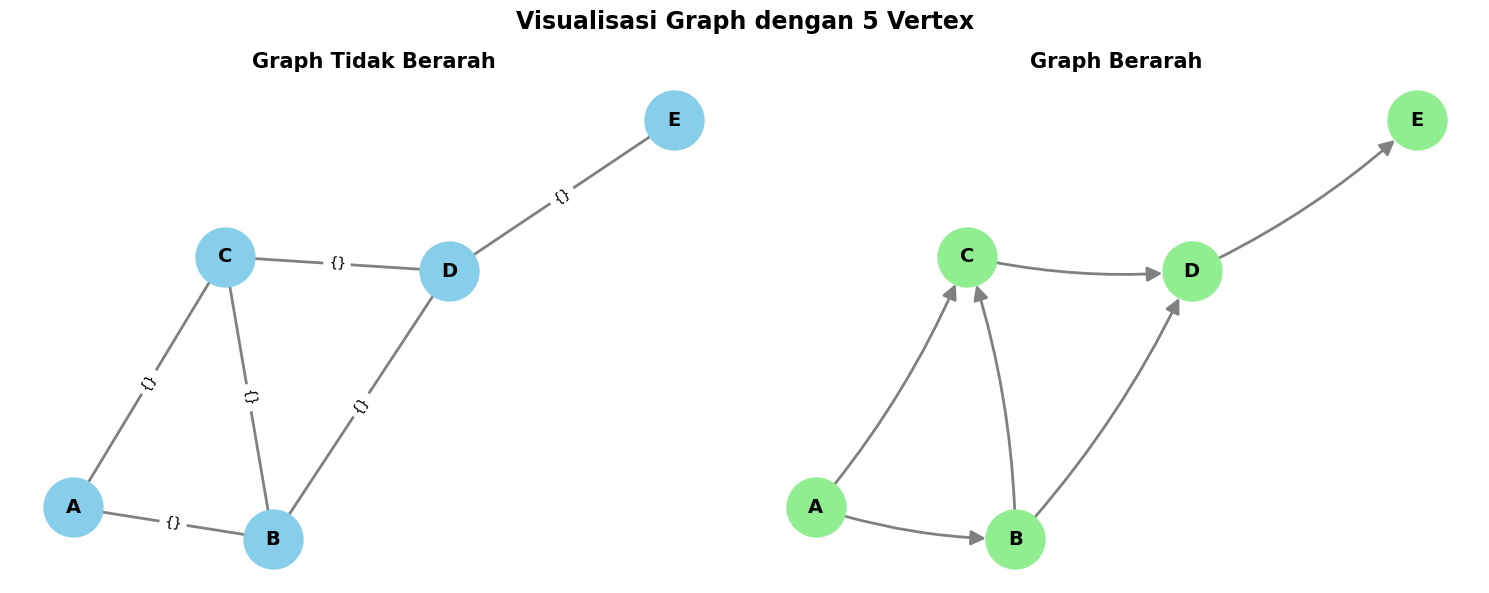

In [37]:
# Menentukan posisi vertex
pos = nx.spring_layout(G1, seed=42)

# Membuat area visualisasi
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ------------------------------------------------------------
# GRAPH TIDAK BERARAH
# ------------------------------------------------------------

nx.draw_networkx(
    G1,
    pos,
    ax=axes[0],
    with_labels=True,
    node_color='skyblue',
    node_size=1800,
    font_size=14,
    font_weight='bold',
    edge_color='gray',
    width=2
)

nx.draw_networkx_edge_labels(
    G1,
    pos,
    ax=axes[0],
    font_size=10
)

axes[0].set_title(
    "Graph Tidak Berarah",
    fontsize=15,
    fontweight='bold'
)

axes[0].axis('off')


# ------------------------------------------------------------
# GRAPH BERARAH
# ------------------------------------------------------------

nx.draw_networkx(
    G2,
    pos,
    ax=axes[1],
    with_labels=True,
    node_color='lightgreen',
    node_size=1800,
    font_size=14,
    font_weight='bold',
    edge_color='gray',
    width=2,
    arrows=True,
    arrowsize=22,
    connectionstyle='arc3,rad=0.08'
)

axes[1].set_title(
    "Graph Berarah",
    fontsize=15,
    fontweight='bold'
)

axes[1].axis('off')

plt.suptitle(
    "Visualisasi Graph dengan 5 Vertex",
    fontsize=17,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


## Bagian C — Analisis degree setiap vertex

### Menghitung degree setiap vertex

Degree merupakan jumlah edge yang terhubung dengan suatu vertex.Untuk graph tidak berarah, kita hanya menghitung degree.

Untuk graph berarah, kita menghitung tiga jenis degree:
1. In-degree: jumlah edge yang masuk ke vertex.
2. Out-degree: jumlah edge yang keluar dari vertex.
3. Total degree: penjumlahan in-degree dan out-degree.

Hasilnya disajikan menggunakan DataFrame.

In [38]:
# ------------------------------------------------------------
# GRAPH TIDAK BERARAH
# ------------------------------------------------------------

degree_undirected = dict(G1.degree())

df_degree_undirected = pd.DataFrame({
    'Vertex': vertices,
    'Degree': [degree_undirected[v] for v in vertices]
})

print("DEGREE GRAPH TIDAK BERARAH")
display(df_degree_undirected)


# ------------------------------------------------------------
# GRAPH BERARAH
# ------------------------------------------------------------

in_degree = dict(G2.in_degree())
out_degree = dict(G2.out_degree())
total_degree = dict(G2.degree())

df_degree_directed = pd.DataFrame({
    'Vertex': vertices,
    'In-Degree': [in_degree[v] for v in vertices],
    'Out-Degree': [out_degree[v] for v in vertices],
    'Total Degree': [total_degree[v] for v in vertices]
})

print("\nDEGREE GRAPH BERARAH")
display(df_degree_directed)


DEGREE GRAPH TIDAK BERARAH


,Vertex,Degree
0,A,2
1,B,3
2,C,3
3,D,3
4,E,1



DEGREE GRAPH BERARAH


,Vertex,In-Degree,Out-Degree,Total Degree
0,A,0,2,2
1,B,1,2,3
2,C,2,1,3
3,D,2,1,3
4,E,1,0,1


### Visualisasi degree setiap vertex

Cell ini merupakan tambahan untuk memperjelas perbedaan degree masing-masing vertex.Grafik pertama menampilkan degree graph tidak berarah.Grafik kedua menampilkan in-degree, out-degree, dan total degree graph berarah.

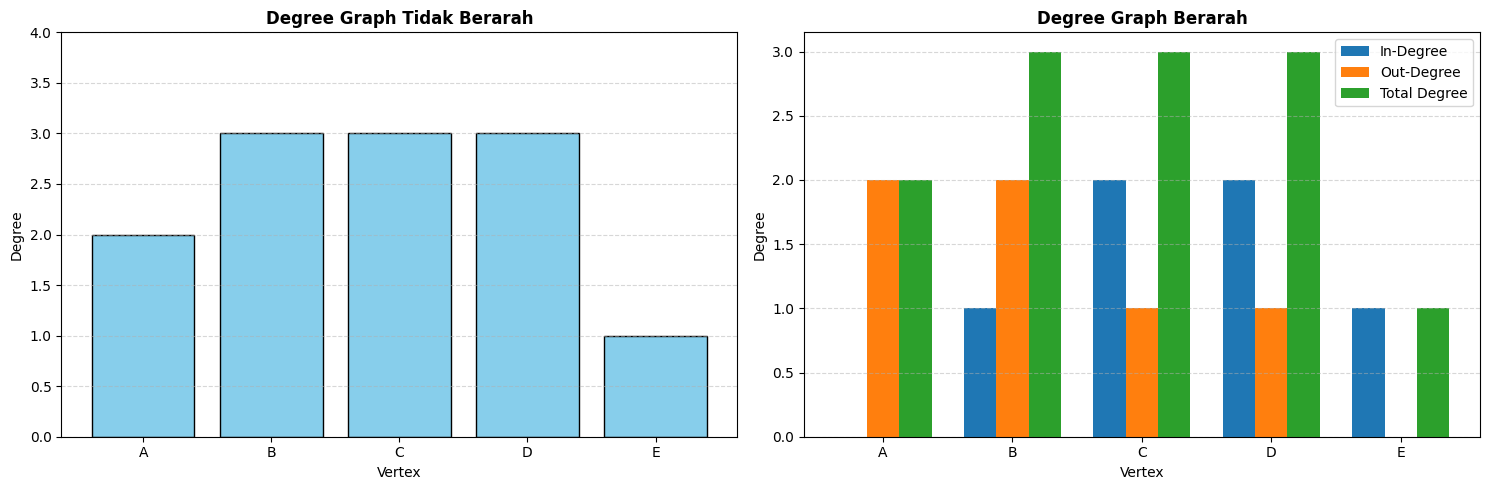

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ------------------------------------------------------------
# DEGREE GRAPH TIDAK BERARAH
# ------------------------------------------------------------

axes[0].bar(
    vertices,
    [degree_undirected[v] for v in vertices],
    color='skyblue',
    edgecolor='black'
)

axes[0].set_title(
    "Degree Graph Tidak Berarah",
    fontweight='bold'
)

axes[0].set_xlabel("Vertex")
axes[0].set_ylabel("Degree")
axes[0].set_ylim(0, max(degree_undirected.values()) + 1)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)


# ------------------------------------------------------------
# DEGREE GRAPH BERARAH
# ------------------------------------------------------------

x = np.arange(len(vertices))
width = 0.25

axes[1].bar(
    x - width,
    [in_degree[v] for v in vertices],
    width,
    label='In-Degree'
)

axes[1].bar(
    x,
    [out_degree[v] for v in vertices],
    width,
    label='Out-Degree'
)

axes[1].bar(
    x + width,
    [total_degree[v] for v in vertices],
    width,
    label='Total Degree'
)

axes[1].set_title(
    "Degree Graph Berarah",
    fontweight='bold'
)

axes[1].set_xlabel("Vertex")
axes[1].set_ylabel("Degree")
axes[1].set_xticks(x)
axes[1].set_xticklabels(vertices)
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Menghitung koefisien klasterisasi setiap vertex

Clustering coefficient merupakan ukuran yang menunjukkan seberapa erat hubungan antara tetangga suatu vertex.

Nilai koefisien klasterisasi berada pada rentang 0 sampai 1.
- Nilai 0 berarti tidak terdapat hubungan antar tetangga.
- Nilai 1 berarti seluruh tetangga saling terhubung.

Untuk graph berarah, NetworkX menggunakan perhitungan koefisien klasterisasi yang mempertimbangkan struktur arah edge.

In [40]:
# ------------------------------------------------------------
# GRAPH TIDAK BERARAH
# ------------------------------------------------------------

clustering_undirected = nx.clustering(G1)

average_clustering_undirected = nx.average_clustering(G1)

df_clustering_undirected = pd.DataFrame({
    'Vertex': vertices,
    'Clustering Coefficient': [
        clustering_undirected[v] for v in vertices
    ]
})

print("CLUSTERING GRAPH TIDAK BERARAH")
display(df_clustering_undirected)

print(
    "Rata-rata Clustering:",
    round(average_clustering_undirected, 4)
)


# ------------------------------------------------------------
# GRAPH BERARAH
# ------------------------------------------------------------

clustering_directed = nx.clustering(G2)

average_clustering_directed = nx.average_clustering(G2)

df_clustering_directed = pd.DataFrame({
    'Vertex': vertices,
    'Clustering Coefficient': [
        clustering_directed[v] for v in vertices
    ]
})

print("\nCLUSTERING GRAPH BERARAH")
display(df_clustering_directed)

print(
    "Rata-rata Clustering:",
    round(average_clustering_directed, 4)
)


CLUSTERING GRAPH TIDAK BERARAH


,Vertex,Clustering Coefficient
0,A,1.0000
1,B,0.6667
2,C,0.6667
3,D,0.3333
4,E,0.0000


Rata-rata Clustering: 0.5333

CLUSTERING GRAPH BERARAH


,Vertex,Clustering Coefficient
0,A,0.5000
1,B,0.3333
2,C,0.3333
3,D,0.1667
4,E,0.0000


Rata-rata Clustering: 0.2667


### Visualisasi koefisien klasterisasi

Cell ini digunakan untuk membandingkan koefisien klasterisasi setiap vertex pada kedua graph.Visualisasi ini membantu mengetahui vertex mana yang memiliki keterhubungan tetangga paling tinggi.

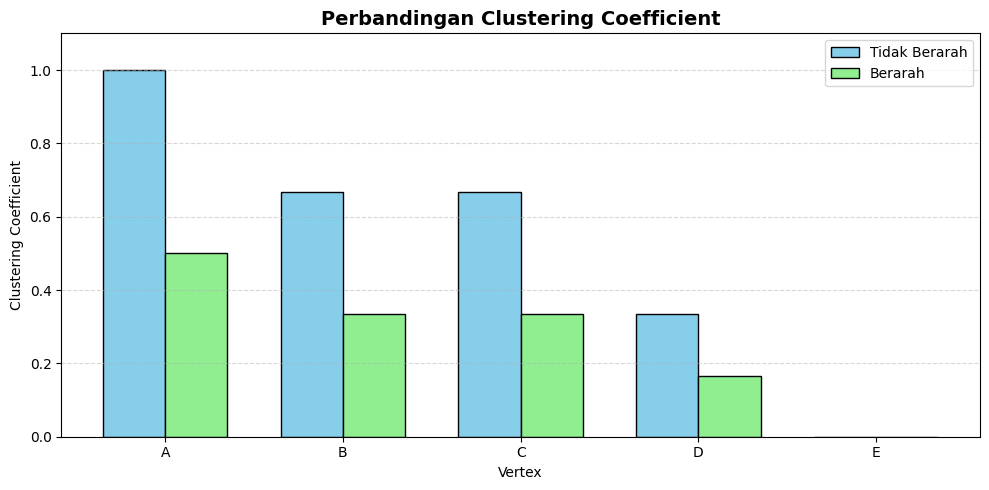

In [41]:
x = np.arange(len(vertices))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    [clustering_undirected[v] for v in vertices],
    width,
    label='Tidak Berarah',
    color='skyblue',
    edgecolor='black'
)

plt.bar(
    x + width / 2,
    [clustering_directed[v] for v in vertices],
    width,
    label='Berarah',
    color='lightgreen',
    edgecolor='black'
)

plt.title(
    "Perbandingan Clustering Coefficient",
    fontsize=14,
    fontweight='bold'
)

plt.xlabel("Vertex")
plt.ylabel("Clustering Coefficient")
plt.xticks(x, vertices)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## Bagian D — Analisis lintasan terpendek

### Menghitung shortest path setiap pasangan vertex

Shortest path merupakan lintasan dengan jumlah edge paling sedikit yang menghubungkan dua vertex.Pada cell ini kita menampilkan lintasan terpendek untuk setiap pasangan vertex.Untuk graph berarah, lintasan hanya dapat mengikuti arah edge. Jika tidak terdapat jalur dari satu vertex ke vertex lainnya, maka akan ditampilkan bahwa jalur tidak tersedia.

In [42]:
def tampilkan_shortest_path(G, nama):

    print("\n" + "=" * 65)
    print("SHORTEST PATH -", nama)
    print("=" * 65)

    hasil = []

    for sumber in vertices:

        for tujuan in vertices:

            if sumber != tujuan:

                try:

                    path = nx.shortest_path(
                        G,
                        source=sumber,
                        target=tujuan
                    )

                    jarak = nx.shortest_path_length(
                        G,
                        source=sumber,
                        target=tujuan
                    )

                    hasil.append({
                        'Sumber': sumber,
                        'Tujuan': tujuan,
                        'Shortest Path': ' -> '.join(path),
                        'Jarak': jarak
                    })

                except nx.NetworkXNoPath:

                    hasil.append({
                        'Sumber': sumber,
                        'Tujuan': tujuan,
                        'Shortest Path': 'Tidak tersedia',
                        'Jarak': np.nan
                    })

    df_path = pd.DataFrame(hasil)

    display(df_path)

    return df_path


# Graph tidak berarah
path_undirected = tampilkan_shortest_path(
    G1,
    "GRAPH TIDAK BERARAH"
)

# Graph berarah
path_directed = tampilkan_shortest_path(
    G2,
    "GRAPH BERARAH"
)



SHORTEST PATH - GRAPH TIDAK BERARAH


,Sumber,Tujuan,Shortest Path,Jarak
0,A,B,A -> B,1
1,A,C,A -> C,1
2,A,D,A -> B -> D,2
3,A,E,A -> B -> D -> E,3
4,B,A,B -> A,1
5,B,C,B -> C,1
6,B,D,B -> D,1
7,B,E,B -> D -> E,2
8,C,A,C -> A,1
9,C,B,C -> B,1



SHORTEST PATH - GRAPH BERARAH


,Sumber,Tujuan,Shortest Path,Jarak
0,A,B,A -> B,1.0
1,A,C,A -> C,1.0
2,A,D,A -> B -> D,2.0
3,A,E,A -> B -> D -> E,3.0
4,B,A,Tidak tersedia,NaN
5,B,C,B -> C,1.0
6,B,D,B -> D,1.0
7,B,E,B -> D -> E,2.0
8,C,A,Tidak tersedia,NaN
9,C,B,Tidak tersedia,NaN


### Menghitung rata-rata lintasan terpendek

Cell ini menghitung Average Shortest Path Length.

Pada graph tidak berarah, rata-rata dihitung dari seluruh pasangan vertex karena graph terhubung.Pada graph berarah, rata-rata standar hanya dapat dihitung apabila graph strongly connected.

Karena graph berarah kita tidak strongly connected, kode akan menampilkan dua hal:
- Nilai rata-rata shortest path standar: tidak terdefinisi.
- Rata-rata jarak untuk seluruh pasangan berarah yang dapat dijangkau: tetap dihitung sebagai informasi tambahan.

In [43]:
# ------------------------------------------------------------
# GRAPH TIDAK BERARAH
# ------------------------------------------------------------

print("GRAPH TIDAK BERARAH")

if nx.is_connected(G1):

    avg_path_undirected = nx.average_shortest_path_length(G1)

    print(
        "Average Shortest Path Length:",
        round(avg_path_undirected, 4)
    )

else:

    avg_path_undirected = None

    print("Graph tidak terhubung.")
    print("Average Shortest Path Length tidak terdefinisi.")


# ------------------------------------------------------------
# GRAPH BERARAH
# ------------------------------------------------------------

print("\nGRAPH BERARAH")

if nx.is_strongly_connected(G2):

    avg_path_directed = nx.average_shortest_path_length(G2)

    print(
        "Average Shortest Path Length:",
        round(avg_path_directed, 4)
    )

else:

    avg_path_directed = None

    print("Graph tidak strongly connected.")
    print("Average Shortest Path Length standar tidak terdefinisi.")

    # Menghitung jarak untuk pasangan vertex yang dapat dijangkau
    semua_jarak = []

    for sumber, jarak_dict in nx.all_pairs_shortest_path_length(G2):

        for tujuan, jarak in jarak_dict.items():

            if sumber != tujuan:

                semua_jarak.append(jarak)

    if semua_jarak:

        avg_reachable_path = np.mean(semua_jarak)

        print(
            "Rata-rata jarak pasangan yang dapat dijangkau:",
            round(avg_reachable_path, 4)
        )

        print(
            "Jumlah pasangan yang dapat dijangkau:",
            len(semua_jarak)
        )

    else:

        avg_reachable_path = np.nan

        print("Tidak ada pasangan vertex yang dapat dijangkau.")


GRAPH TIDAK BERARAH
Average Shortest Path Length: 1.5

GRAPH BERARAH
Graph tidak strongly connected.
Average Shortest Path Length standar tidak terdefinisi.
Rata-rata jarak pasangan yang dapat dijangkau: 1.5
Jumlah pasangan yang dapat dijangkau: 10


## Bagian E — Analisis rata-rata degree dan density

### Menghitung rata-rata degree

Rata-rata degree diperoleh dengan menjumlahkan seluruh degree vertex kemudian membaginya dengan jumlah vertex.

Untuk graph berarah, kita juga menghitung rata-rata in-degree dan out-degree secara terpisah.

Perlu diingat bahwa rata-rata total degree graph berarah adalah dua kali rata-rata in-degree atau out-degree apabila seluruh edge dihitung satu kali.

In [44]:
jumlah_vertex = len(vertices)

# ------------------------------------------------------------
# GRAPH TIDAK BERARAH
# ------------------------------------------------------------

total_degree_undirected = sum(degree_undirected.values())

average_degree_undirected = (
    total_degree_undirected / jumlah_vertex
)

print("GRAPH TIDAK BERARAH")
print("Total Degree:", total_degree_undirected)
print("Jumlah Vertex:", jumlah_vertex)

print(
    "Rata-rata Degree:",
    round(average_degree_undirected, 4)
)


# ------------------------------------------------------------
# GRAPH BERARAH
# ------------------------------------------------------------

total_in_degree = sum(in_degree.values())
total_out_degree = sum(out_degree.values())
total_degree_directed = sum(total_degree.values())

average_in_degree = total_in_degree / jumlah_vertex
average_out_degree = total_out_degree / jumlah_vertex

average_degree_directed = (
    total_degree_directed / jumlah_vertex
)

print("\nGRAPH BERARAH")

print("Total In-Degree:", total_in_degree)
print("Total Out-Degree:", total_out_degree)
print("Total Degree:", total_degree_directed)

print("Rata-rata In-Degree:", round(average_in_degree, 4))
print("Rata-rata Out-Degree:", round(average_out_degree, 4))

print(
    "Rata-rata Total Degree:",
    round(average_degree_directed, 4)
)


GRAPH TIDAK BERARAH
Total Degree: 12
Jumlah Vertex: 5
Rata-rata Degree: 2.4

GRAPH BERARAH
Total In-Degree: 6
Total Out-Degree: 6
Total Degree: 12
Rata-rata In-Degree: 1.2
Rata-rata Out-Degree: 1.2
Rata-rata Total Degree: 2.4


### Menghitung density graph

Density merupakan ukuran yang menunjukkan tingkat kepadatan hubungan dalam graph.Semakin mendekati 1, semakin padat hubungan antarvertex.


DENSITY GRAPH TIDAK BERARAH
Jumlah Vertex: 5
Jumlah Edge: 6
Density: 0.6

DENSITY GRAPH BERARAH
Jumlah Vertex: 5
Jumlah Edge: 6
Density: 0.3


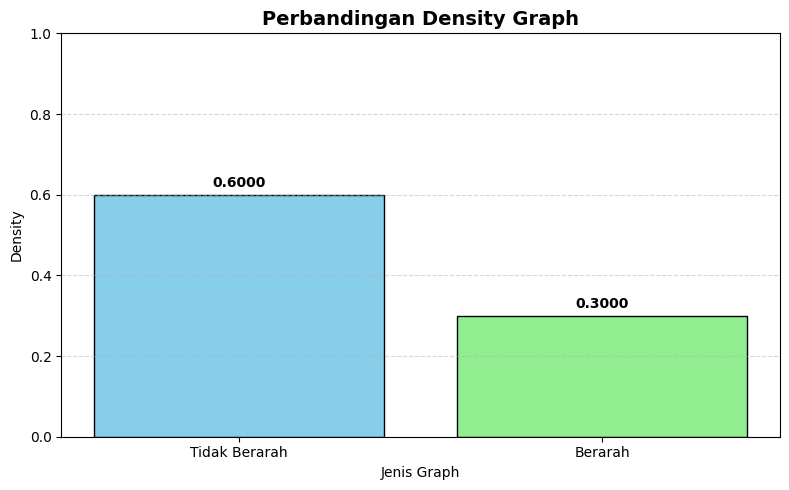

In [45]:
# Density graph tidak berarah
density_undirected = nx.density(G1)

# Density graph berarah
density_directed = nx.density(G2)

print("DENSITY GRAPH TIDAK BERARAH")
print("Jumlah Vertex:", G1.number_of_nodes())
print("Jumlah Edge:", G1.number_of_edges())
print("Density:", round(density_undirected, 4))


print("\nDENSITY GRAPH BERARAH")
print("Jumlah Vertex:", G2.number_of_nodes())
print("Jumlah Edge:", G2.number_of_edges())
print("Density:", round(density_directed, 4))


# Visualisasi perbandingan density

plt.figure(figsize=(8, 5))

nama_graph = [
    'Tidak Berarah',
    'Berarah'
]

nilai_density = [
    density_undirected,
    density_directed
]

plt.bar(
    nama_graph,
    nilai_density,
    color=['skyblue', 'lightgreen'],
    edgecolor='black'
)

plt.title(
    "Perbandingan Density Graph",
    fontsize=14,
    fontweight='bold'
)

plt.xlabel("Jenis Graph")
plt.ylabel("Density")
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, nilai in enumerate(nilai_density):

    plt.text(
        i,
        nilai + 0.02,
        f"{nilai:.4f}",
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


### Perhitungan Manual Degree Graph Tidak Berarah
Menghitung distribusi degree pada Undirected Graph (G1).

In [46]:

# ==========================================
# PERHITUNGAN MANUAL DISTRIBUSI DEGREE
# UNDIRECTED GRAPH
# ==========================================

print("=" * 60)
print("PERHITUNGAN MANUAL DISTRIBUSI DEGREE UNDIRECTED GRAPH")
print("=" * 60)

# Mengambil degree setiap vertex
degree_undirected = dict(G1.degree())

# Menghitung jumlah seluruh vertex
N = G1.number_of_nodes()

print("\n1. Degree Setiap Vertex:")
for vertex, degree in degree_undirected.items():
    print(f"Vertex {vertex}: Degree = {degree}")

# Mengambil nilai degree yang berbeda
nilai_degree = sorted(set(degree_undirected.values()))

print("\n2. Perhitungan Distribusi Derajat:")

hasil_manual_undirected = {}

for k in nilai_degree:

    # Menghitung jumlah vertex dengan degree k
    Nk = 0

    for vertex, degree in degree_undirected.items():
        if degree == k:
            Nk += 1

    # Menghitung probabilitas
    Pk = Nk / N

    hasil_manual_undirected[k] = Pk

    # Menampilkan proses perhitungan
    print(f"\nDegree k = {k}")
    print(f"N_k = {Nk}")
    print(f"N = {N}")
    print(f"P({k}) = N_k / N")
    print(f"P({k}) = {Nk} / {N}")
    print(f"P({k}) = {Pk:.4f}")

# Menampilkan tabel hasil
print("\n3. Hasil Distribusi Degree Undirected Graph:")
print("-" * 45)
print(f"{'Degree (k)':<15}{'Jumlah Vertex':<15}{'P(k)':<10}")
print("-" * 45)

for k in nilai_degree:
    Nk = sum(1 for d in degree_undirected.values() if d == k)
    print(f"{k:<15}{Nk:<15}{hasil_manual_undirected[k]:<10.4f}")

print("-" * 45)
print(f"Total Probabilitas = {sum(hasil_manual_undirected.values()):.4f}")


PERHITUNGAN MANUAL DISTRIBUSI DEGREE UNDIRECTED GRAPH

1. Degree Setiap Vertex:
Vertex A: Degree = 2
Vertex B: Degree = 3
Vertex C: Degree = 3
Vertex D: Degree = 3
Vertex E: Degree = 1

2. Perhitungan Distribusi Derajat:

Degree k = 1
N_k = 1
N = 5
P(1) = N_k / N
P(1) = 1 / 5
P(1) = 0.2000

Degree k = 2
N_k = 1
N = 5
P(2) = N_k / N
P(2) = 1 / 5
P(2) = 0.2000

Degree k = 3
N_k = 3
N = 5
P(3) = N_k / N
P(3) = 3 / 5
P(3) = 0.6000

3. Hasil Distribusi Degree Undirected Graph:
---------------------------------------------
Degree (k)     Jumlah Vertex  P(k)      
---------------------------------------------
1              1              0.2000    
2              1              0.2000    
3              3              0.6000    
---------------------------------------------
Total Probabilitas = 1.0000


### Perhitungan Manual Total Degree Graph Berarah
Menghitung distribusi total degree pada Directed Graph (G2).

In [47]:

# ==========================================
# PERHITUNGAN MANUAL DISTRIBUSI TOTAL DEGREE
# DIRECTED GRAPH
# ==========================================

print("=" * 60)
print("PERHITUNGAN MANUAL TOTAL DEGREE DIRECTED GRAPH")
print("=" * 60)

# Mengambil total degree setiap vertex
degree_directed_total = dict(G2.degree())

# Menghitung jumlah seluruh vertex
N = G2.number_of_nodes()

print("\n1. Total Degree Setiap Vertex:")
for vertex in G2.nodes():

    in_degree = G2.in_degree(vertex)
    out_degree = G2.out_degree(vertex)
    total_degree = in_degree + out_degree

    print(
        f"Vertex {vertex}: "
        f"In-Degree = {in_degree}, "
        f"Out-Degree = {out_degree}, "
        f"Total Degree = {total_degree}"
    )

# Mengambil nilai total degree yang berbeda
nilai_degree = sorted(set(degree_directed_total.values()))

print("\n2. Perhitungan Distribusi Total Degree:")

hasil_manual_directed_total = {}

for k in nilai_degree:

    # Menghitung jumlah vertex dengan total degree k
    Nk = 0

    for vertex, degree in degree_directed_total.items():
        if degree == k:
            Nk += 1

    # Menghitung probabilitas
    Pk = Nk / N

    hasil_manual_directed_total[k] = Pk

    print(f"\nTotal Degree k = {k}")
    print(f"N_k = {Nk}")
    print(f"N = {N}")
    print(f"P({k}) = N_k / N")
    print(f"P({k}) = {Nk} / {N}")
    print(f"P({k}) = {Pk:.4f}")

# Menampilkan tabel hasil
print("\n3. Hasil Distribusi Total Degree:")
print("-" * 45)
print(f"{'Degree (k)':<15}{'Jumlah Vertex':<15}{'P(k)':<10}")
print("-" * 45)

for k in nilai_degree:
    Nk = sum(1 for d in degree_directed_total.values() if d == k)
    print(f"{k:<15}{Nk:<15}{hasil_manual_directed_total[k]:<10.4f}")

print("-" * 45)
print(f"Total Probabilitas = {sum(hasil_manual_directed_total.values()):.4f}")

PERHITUNGAN MANUAL TOTAL DEGREE DIRECTED GRAPH

1. Total Degree Setiap Vertex:
Vertex A: In-Degree = 0, Out-Degree = 2, Total Degree = 2
Vertex B: In-Degree = 1, Out-Degree = 2, Total Degree = 3
Vertex C: In-Degree = 2, Out-Degree = 1, Total Degree = 3
Vertex D: In-Degree = 2, Out-Degree = 1, Total Degree = 3
Vertex E: In-Degree = 1, Out-Degree = 0, Total Degree = 1

2. Perhitungan Distribusi Total Degree:

Total Degree k = 1
N_k = 1
N = 5
P(1) = N_k / N
P(1) = 1 / 5
P(1) = 0.2000

Total Degree k = 2
N_k = 1
N = 5
P(2) = N_k / N
P(2) = 1 / 5
P(2) = 0.2000

Total Degree k = 3
N_k = 3
N = 5
P(3) = N_k / N
P(3) = 3 / 5
P(3) = 0.6000

3. Hasil Distribusi Total Degree:
---------------------------------------------
Degree (k)     Jumlah Vertex  P(k)      
---------------------------------------------
1              1              0.2000    
2              1              0.2000    
3              3              0.6000    
---------------------------------------------
Total Probabilitas = 1.00

### Perhitungan Manual In-Degree Graph Berarah
Menghitung distribusi in-degree pada Directed Graph (G2).

In [48]:

# ==========================================
# PERHITUNGAN MANUAL DISTRIBUSI IN-DEGREE
# DIRECTED GRAPH
# ==========================================

print("=" * 60)
print("PERHITUNGAN MANUAL DISTRIBUSI IN-DEGREE")
print("=" * 60)

# Mengambil in-degree setiap vertex
degree_in = dict(G2.in_degree())

# Menghitung jumlah seluruh vertex
N = G2.number_of_nodes()

print("\n1. In-Degree Setiap Vertex:")
for vertex, degree in degree_in.items():
    print(f"Vertex {vertex}: In-Degree = {degree}")

# Mengambil nilai in-degree yang berbeda
nilai_degree = sorted(set(degree_in.values()))

print("\n2. Perhitungan Distribusi In-Degree:")

hasil_manual_in_degree = {}

for k in nilai_degree:

    # Menghitung jumlah vertex dengan in-degree k
    Nk = 0

    for vertex, degree in degree_in.items():
        if degree == k:
            Nk += 1

    # Menghitung probabilitas
    Pk = Nk / N

    hasil_manual_in_degree[k] = Pk

    print(f"\nIn-Degree k = {k}")
    print(f"N_k = {Nk}")
    print(f"N = {N}")
    print(f"P({k}) = N_k / N")
    print(f"P({k}) = {Nk} / {N}")
    print(f"P({k}) = {Pk:.4f}")

# Menampilkan tabel hasil
print("\n3. Hasil Distribusi In-Degree:")
print("-" * 45)
print(f"{'In-Degree (k)':<15}{'Jumlah Vertex':<15}{'P(k)':<10}")
print("-" * 45)

for k in nilai_degree:
    Nk = sum(1 for d in degree_in.values() if d == k)
    print(f"{k:<15}{Nk:<15}{hasil_manual_in_degree[k]:<10.4f}")

print("-" * 45)
print(f"Total Probabilitas = {sum(hasil_manual_in_degree.values()):.4f}")

PERHITUNGAN MANUAL DISTRIBUSI IN-DEGREE

1. In-Degree Setiap Vertex:
Vertex A: In-Degree = 0
Vertex B: In-Degree = 1
Vertex C: In-Degree = 2
Vertex D: In-Degree = 2
Vertex E: In-Degree = 1

2. Perhitungan Distribusi In-Degree:

In-Degree k = 0
N_k = 1
N = 5
P(0) = N_k / N
P(0) = 1 / 5
P(0) = 0.2000

In-Degree k = 1
N_k = 2
N = 5
P(1) = N_k / N
P(1) = 2 / 5
P(1) = 0.4000

In-Degree k = 2
N_k = 2
N = 5
P(2) = N_k / N
P(2) = 2 / 5
P(2) = 0.4000

3. Hasil Distribusi In-Degree:
---------------------------------------------
In-Degree (k)  Jumlah Vertex  P(k)      
---------------------------------------------
0              1              0.2000    
1              2              0.4000    
2              2              0.4000    
---------------------------------------------
Total Probabilitas = 1.0000


### Perhitungan Manual Out-Degree Graph Berarah
Menghitung distribusi out-degree pada Directed Graph (G2).

In [49]:

# ==========================================
# PERHITUNGAN MANUAL DISTRIBUSI OUT-DEGREE
# DIRECTED GRAPH
# ==========================================

print("=" * 60)
print("PERHITUNGAN MANUAL DISTRIBUSI OUT-DEGREE")
print("=" * 60)

# Mengambil out-degree setiap vertex
degree_out = dict(G2.out_degree())

# Menghitung jumlah seluruh vertex
N = G2.number_of_nodes()

print("\n1. Out-Degree Setiap Vertex:")
for vertex, degree in degree_out.items():
    print(f"Vertex {vertex}: Out-Degree = {degree}")

# Mengambil nilai out-degree yang berbeda
nilai_degree = sorted(set(degree_out.values()))

print("\n2. Perhitungan Distribusi Out-Degree:")

hasil_manual_out_degree = {}

for k in nilai_degree:

    # Menghitung jumlah vertex dengan out-degree k
    Nk = 0

    for vertex, degree in degree_out.items():
        if degree == k:
            Nk += 1

    # Menghitung probabilitas
    Pk = Nk / N

    hasil_manual_out_degree[k] = Pk

    print(f"\nOut-Degree k = {k}")
    print(f"N_k = {Nk}")
    print(f"N = {N}")
    print(f"P({k}) = N_k / N")
    print(f"P({k}) = {Nk} / {N}")
    print(f"P({k}) = {Pk:.4f}")

# Menampilkan tabel hasil
print("\n3. Hasil Distribusi Out-Degree:")
print("-" * 45)
print(f"{'Out-Degree (k)':<15}{'Jumlah Vertex':<15}{'P(k)':<10}")
print("-" * 45)

for k in nilai_degree:
    Nk = sum(1 for d in degree_out.values() if d == k)
    print(f"{k:<15}{Nk:<15}{hasil_manual_out_degree[k]:<10.4f}")

print("-" * 45)
print(f"Total Probabilitas = {sum(hasil_manual_out_degree.values()):.4f}")

PERHITUNGAN MANUAL DISTRIBUSI OUT-DEGREE

1. Out-Degree Setiap Vertex:
Vertex A: Out-Degree = 2
Vertex B: Out-Degree = 2
Vertex C: Out-Degree = 1
Vertex D: Out-Degree = 1
Vertex E: Out-Degree = 0

2. Perhitungan Distribusi Out-Degree:

Out-Degree k = 0
N_k = 1
N = 5
P(0) = N_k / N
P(0) = 1 / 5
P(0) = 0.2000

Out-Degree k = 1
N_k = 2
N = 5
P(1) = N_k / N
P(1) = 2 / 5
P(1) = 0.4000

Out-Degree k = 2
N_k = 2
N = 5
P(2) = N_k / N
P(2) = 2 / 5
P(2) = 0.4000

3. Hasil Distribusi Out-Degree:
---------------------------------------------
Out-Degree (k) Jumlah Vertex  P(k)      
---------------------------------------------
0              1              0.2000    
1              2              0.4000    
2              2              0.4000    
---------------------------------------------
Total Probabilitas = 1.0000


## Bagian F — Degree distribution

### Menghitung Distribusi Derajat

Degree distribution atau distribusi derajat menunjukkan persebaran jumlah *vertex* berdasarkan nilai *degree* yang dimiliki. Analisis ini digunakan untuk mengetahui berapa banyak *vertex* yang memiliki jumlah hubungan atau koneksi tertentu dalam suatu graph.

Pada bagian ini, kita akan menghitung empat jenis distribusi derajat, yaitu:

1. Distribusi *degree* pada graph tidak berarah (*undirected graph*).
2. Distribusi *total degree* pada graph berarah (*directed graph*).
3. Distribusi *in-degree* pada graph berarah.
4. Distribusi *out-degree* pada graph berarah.


Nilai probabilitas menunjukkan proporsi *vertex* yang memiliki degree tertentu terhadap keseluruhan jumlah *vertex* dalam graph.

In [51]:
from collections import Counter
import pandas as pd

# ============================================================
# MENYIAPKAN DATA DEGREE SETIAP GRAPH
# ============================================================

# Degree graph tidak berarah
degree_undirected = dict(G1.degree())

# Total degree graph berarah
degree_directed_total = dict(G2.degree())

# In-degree graph berarah
degree_directed_in = dict(G2.in_degree())

# Out-degree graph berarah
degree_directed_out = dict(G2.out_degree())


# ============================================================
# FUNGSI MENGHITUNG DISTRIBUSI DEGREE
# ============================================================

def hitung_distribusi(data_degree, nama):

    # Menghitung jumlah vertex berdasarkan degree
    distribusi = Counter(data_degree.values())

    hasil = []

    # Menghitung probabilitas setiap degree
    for k in sorted(distribusi.keys()):

        jumlah = distribusi[k]
        probabilitas = jumlah / len(data_degree)

        hasil.append({
            'Degree (k)': k,
            'Jumlah Vertex': jumlah,
            'Probabilitas P(k)': probabilitas
        })

    # Membuat DataFrame
    df = pd.DataFrame(hasil)

    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    display(df)

    return df


# ============================================================
# 1. DISTRIBUSI DEGREE GRAPH TIDAK BERARAH
# ============================================================

distribusi_undirected = hitung_distribusi(
    degree_undirected,
    "DISTRIBUSI DEGREE GRAPH TIDAK BERARAH"
)


# ============================================================
# 2. DISTRIBUSI TOTAL DEGREE GRAPH BERARAH
# ============================================================

distribusi_directed = hitung_distribusi(
    degree_directed_total,
    "DISTRIBUSI TOTAL DEGREE GRAPH BERARAH"
)


# ============================================================
# 3. DISTRIBUSI IN-DEGREE GRAPH BERARAH
# ============================================================

distribusi_in = hitung_distribusi(
    degree_directed_in,
    "DISTRIBUSI IN-DEGREE GRAPH BERARAH"
)


# ============================================================
# 4. DISTRIBUSI OUT-DEGREE GRAPH BERARAH
# ============================================================

distribusi_out = hitung_distribusi(
    degree_directed_out,
    "DISTRIBUSI OUT-DEGREE GRAPH BERARAH"
)



DISTRIBUSI DEGREE GRAPH TIDAK BERARAH


,Degree (k),Jumlah Vertex,Probabilitas P(k)
0,1,1,0.2
1,2,1,0.2
2,3,3,0.6



DISTRIBUSI TOTAL DEGREE GRAPH BERARAH


,Degree (k),Jumlah Vertex,Probabilitas P(k)
0,1,1,0.2
1,2,1,0.2
2,3,3,0.6



DISTRIBUSI IN-DEGREE GRAPH BERARAH


,Degree (k),Jumlah Vertex,Probabilitas P(k)
0,0,1,0.2
1,1,2,0.4
2,2,2,0.4



DISTRIBUSI OUT-DEGREE GRAPH BERARAH


,Degree (k),Jumlah Vertex,Probabilitas P(k)
0,0,1,0.2
1,1,2,0.4
2,2,2,0.4


### Visualisasi degree distribution

Cell ini digunakan untuk menampilkan distribusi derajat dalam bentuk grafik batang.

Sumbu X menunjukkan nilai degree (k), sedangkan sumbu Y menunjukkan probabilitas P(k).

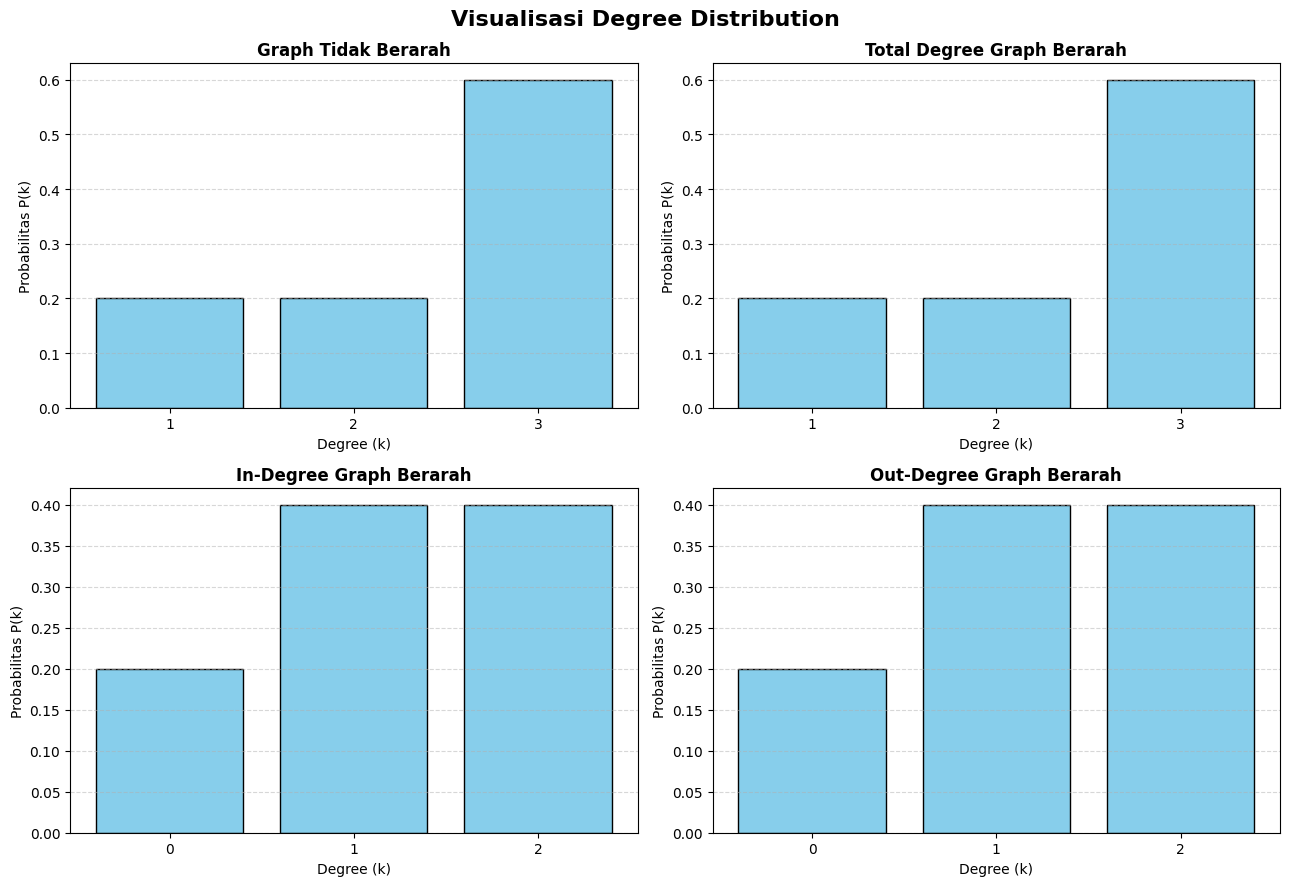

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

data_grafik = [
    (
        distribusi_undirected,
        'Graph Tidak Berarah'
    ),
    (
        distribusi_directed,
        'Total Degree Graph Berarah'
    ),
    (
        distribusi_in,
        'In-Degree Graph Berarah'
    ),
    (
        distribusi_out,
        'Out-Degree Graph Berarah'
    )
]

for ax, (df, judul) in zip(axes.flatten(), data_grafik):

    ax.bar(
        df['Degree (k)'],
        df['Probabilitas P(k)'],
        color='skyblue',
        edgecolor='black'
    )

    ax.set_title(judul, fontweight='bold')
    ax.set_xlabel('Degree (k)')
    ax.set_ylabel('Probabilitas P(k)')

    ax.set_xticks(df['Degree (k)'])

    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.5
    )

plt.suptitle(
    "Visualisasi Degree Distribution",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


## Bagian G — Adjacency matrix

### Membuat adjacency matrix

Adjacency matrix adalah matriks yang menunjukkan hubungan antara setiap pasangan vertex.

Pada matriks:
- Angka 1 berarti terdapat edge.
- Angka 0 berarti tidak terdapat edge.
- Baris menunjukkan vertex asal.
- Kolom menunjukkan vertex tujuan.

Pada graph tidak berarah, adjacency matrix akan simetris terhadap diagonal utama. Pada graph berarah, matriks tidak harus simetris.

In [53]:
# ------------------------------------------------------------
# ADJACENCY MATRIX GRAPH TIDAK BERARAH
# ------------------------------------------------------------

matrix_undirected = nx.to_numpy_array(
    G1,
    nodelist=vertices,
    dtype=int
)

df_matrix_undirected = pd.DataFrame(
    matrix_undirected,
    index=vertices,
    columns=vertices
)

print("ADJACENCY MATRIX GRAPH TIDAK BERARAH")
display(df_matrix_undirected)


# ------------------------------------------------------------
# ADJACENCY MATRIX GRAPH BERARAH
# ------------------------------------------------------------

matrix_directed = nx.to_numpy_array(
    G2,
    nodelist=vertices,
    dtype=int
)

df_matrix_directed = pd.DataFrame(
    matrix_directed,
    index=vertices,
    columns=vertices
)

print("\nADJACENCY MATRIX GRAPH BERARAH")
display(df_matrix_directed)


ADJACENCY MATRIX GRAPH TIDAK BERARAH


,A,B,C,D,E
A,0,1,1,0,0
B,1,0,1,1,0
C,1,1,0,1,0
D,0,1,1,0,1
E,0,0,0,1,0



ADJACENCY MATRIX GRAPH BERARAH


,A,B,C,D,E
A,0,1,1,0,0
B,0,0,1,1,0
C,0,0,0,1,0
D,0,0,0,0,1
E,0,0,0,0,0


### Visualisasi adjacency matrix menggunakan heatmap

Cell ini merupakan tambahan agar adjacency matrix tidak hanya ditampilkan dalam bentuk tabel angka, tetapi juga dalam bentuk visualisasi heatmap.

Warna yang berbeda menunjukkan ada atau tidaknya hubungan antarvertex.

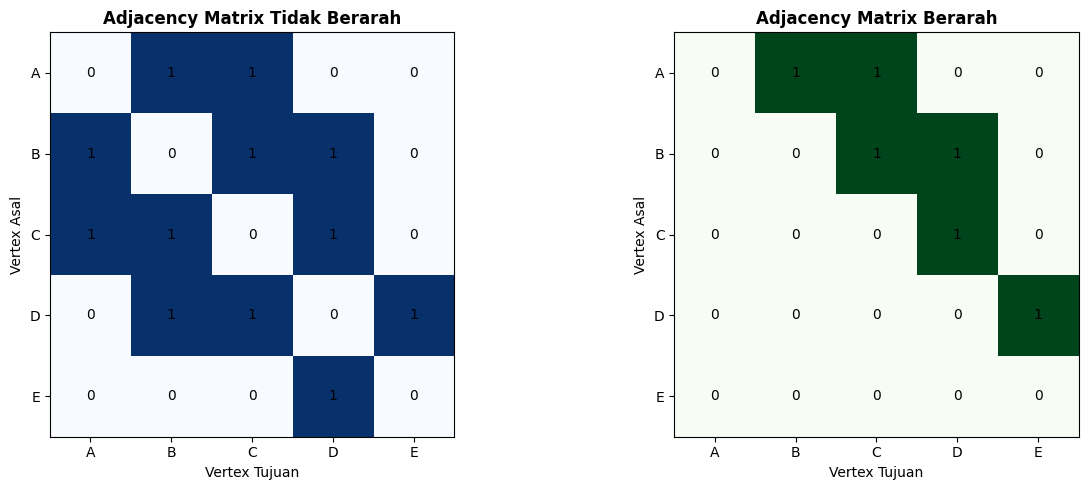

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ------------------------------------------------------------
# HEATMAP GRAPH TIDAK BERARAH
# ------------------------------------------------------------

im1 = axes[0].imshow(
    matrix_undirected,
    cmap='Blues',
    vmin=0,
    vmax=1
)

axes[0].set_title(
    "Adjacency Matrix Tidak Berarah",
    fontweight='bold'
)

axes[0].set_xticks(range(len(vertices)))
axes[0].set_yticks(range(len(vertices)))

axes[0].set_xticklabels(vertices)
axes[0].set_yticklabels(vertices)

axes[0].set_xlabel("Vertex Tujuan")
axes[0].set_ylabel("Vertex Asal")

for i in range(len(vertices)):

    for j in range(len(vertices)):

        axes[0].text(
            j,
            i,
            matrix_undirected[i, j],
            ha='center',
            va='center',
            color='black'
        )


# ------------------------------------------------------------
# HEATMAP GRAPH BERARAH
# ------------------------------------------------------------

im2 = axes[1].imshow(
    matrix_directed,
    cmap='Greens',
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "Adjacency Matrix Berarah",
    fontweight='bold'
)

axes[1].set_xticks(range(len(vertices)))
axes[1].set_yticks(range(len(vertices)))

axes[1].set_xticklabels(vertices)
axes[1].set_yticklabels(vertices)

axes[1].set_xlabel("Vertex Tujuan")
axes[1].set_ylabel("Vertex Asal")

for i in range(len(vertices)):

    for j in range(len(vertices)):

        axes[1].text(
            j,
            i,
            matrix_directed[i, j],
            ha='center',
            va='center',
            color='black'
        )

plt.tight_layout()
plt.show()


## Bagian H — Analisis tambahan

### Menghitung centrality setiap vertex

Tiga centrality yang digunakan:
1. Degree centrality: mengukur proporsi hubungan suatu vertex terhadap vertex lainnya.
2. Betweenness centrality: mengukur seberapa sering suatu vertex menjadi perantara lintasan terpendek.
3. Closeness centrality: mengukur kedekatan suatu vertex terhadap vertex lainnya.

In [55]:
def analisis_centrality(G, nama):

    print("=" * 55)
    print("CENTRALITY ANALYSIS:", nama)
    print("=" * 55)

    # Degree centrality
    degree_centrality = nx.degree_centrality(G)

    # Betweenness centrality
    betweenness = nx.betweenness_centrality(G)

    # Closeness centrality
    closeness = nx.closeness_centrality(G)

    # Membuat tabel hasil
    df = pd.DataFrame({
        'Vertex': vertices,
        'Degree Centrality': [
            degree_centrality[v] for v in vertices
        ],
        'Betweenness Centrality': [
            betweenness[v] for v in vertices
        ],
        'Closeness Centrality': [
            closeness[v] for v in vertices
        ]
    })

    display(df)

    return df


# Centrality graph tidak berarah
centrality_undirected = analisis_centrality(
    G1,
    "GRAPH TIDAK BERARAH"
)


# Centrality graph berarah
centrality_directed = analisis_centrality(
    G2,
    "GRAPH BERARAH"
)


CENTRALITY ANALYSIS: GRAPH TIDAK BERARAH


,Vertex,Degree Centrality,Betweenness Centrality,Closeness Centrality
0,A,0.50,0.0000,0.5714
1,B,0.75,0.1667,0.8000
2,C,0.75,0.1667,0.8000
3,D,0.75,0.5000,0.8000
4,E,0.25,0.0000,0.5000


CENTRALITY ANALYSIS: GRAPH BERARAH


,Vertex,Degree Centrality,Betweenness Centrality,Closeness Centrality
0,A,0.50,0.0000,0.0000
1,B,0.75,0.0833,0.2500
2,C,0.75,0.0833,0.5000
3,D,0.75,0.2500,0.5625
4,E,0.25,0.0000,0.5000


### Membuat tabel perbandingan seluruh metrik graph

Cell ini menggabungkan hasil analisis kedua graph menjadi satu tabel perbandingan.

Dengan begitu, tidak perlu mencari hasil satu per satu dari cell sebelumnya ketika membuat laporan.

In [56]:
# Menyiapkan data perbandingan
perbandingan = pd.DataFrame({

    'Parameter': [
        'Jumlah Vertex',
        'Jumlah Edge',
        'Rata-rata Degree',
        'Rata-rata Clustering',
        'Average Shortest Path',
        'Average Reachable Path',
        'Density',
        'Connected',
        'Strongly Connected'
    ],

    'Graph Tidak Berarah': [
        G1.number_of_nodes(),
        G1.number_of_edges(),
        average_degree_undirected,
        average_clustering_undirected,
        avg_path_undirected,
        avg_path_undirected,
        density_undirected,
        nx.is_connected(G1),
        'Tidak berlaku'
    ],

    'Graph Berarah': [
        G2.number_of_nodes(),
        G2.number_of_edges(),
        average_degree_directed,
        average_clustering_directed,
        avg_path_directed,
        avg_reachable_path,
        density_directed,
        nx.is_weakly_connected(G2),
        nx.is_strongly_connected(G2)
    ]
})

print("TABEL PERBANDINGAN GRAPH")
display(perbandingan)


TABEL PERBANDINGAN GRAPH


,Parameter,Graph Tidak Berarah,Graph Berarah
0,Jumlah Vertex,5,5
1,Jumlah Edge,6,6
2,Rata-rata Degree,2.4,2.4
3,Rata-rata Clustering,0.5333,0.2667
4,Average Shortest Path,1.5,None
5,Average Reachable Path,1.5,1.5
6,Density,0.6,0.3
7,Connected,True,True
8,Strongly Connected,Tidak berlaku,False


### Kesimpulan otomatis hasil analisis

Kesimpulan ini membantu kamu melihat perbedaan karakteristik kedua graph berdasarkan nilai yang telah dihitung sebelumnya.

In [57]:
print("=" * 65)
print("KESIMPULAN ANALISIS GRAPH")
print("=" * 65)

print("\n1. GRAPH TIDAK BERARAH")

print(
    f"Graph memiliki {G1.number_of_nodes()} vertex "
    f"dan {G1.number_of_edges()} edge."
)

print(
    f"Rata-rata degree sebesar "
    f"{average_degree_undirected:.4f}."
)

print(
    f"Rata-rata clustering coefficient sebesar "
    f"{average_clustering_undirected:.4f}."
)

print(
    f"Average shortest path sebesar "
    f"{avg_path_undirected:.4f}."
)

print(
    f"Density graph sebesar "
    f"{density_undirected:.4f}."
)


print("\n2. GRAPH BERARAH")

print(
    f"Graph memiliki {G2.number_of_nodes()} vertex "
    f"dan {G2.number_of_edges()} edge."
)

print(
    f"Rata-rata total degree sebesar "
    f"{average_degree_directed:.4f}."
)

print(
    f"Rata-rata clustering coefficient sebesar "
    f"{average_clustering_directed:.4f}."
)

print(
    f"Density graph sebesar "
    f"{density_directed:.4f}."
)

print(
    f"Rata-rata jarak pasangan yang dapat dijangkau "
    f"sebesar {avg_reachable_path:.4f}."
)

print(
    "\nGraph berarah tidak strongly connected, "
    "sehingga average shortest path standar "
    "tidak terdefinisi."
)


print("\n3. PERBANDINGAN")

if density_undirected > density_directed:

    print(
        "Graph tidak berarah memiliki density "
        "lebih tinggi dibandingkan graph berarah."
    )

if average_clustering_undirected > average_clustering_directed:

    print(
        "Graph tidak berarah memiliki rata-rata "
        "clustering coefficient lebih tinggi."
    )

print("\nAnalisis graph selesai!")


KESIMPULAN ANALISIS GRAPH

1. GRAPH TIDAK BERARAH
Graph memiliki 5 vertex dan 6 edge.
Rata-rata degree sebesar 2.4000.
Rata-rata clustering coefficient sebesar 0.5333.
Average shortest path sebesar 1.5000.
Density graph sebesar 0.6000.

2. GRAPH BERARAH
Graph memiliki 5 vertex dan 6 edge.
Rata-rata total degree sebesar 2.4000.
Rata-rata clustering coefficient sebesar 0.2667.
Density graph sebesar 0.3000.
Rata-rata jarak pasangan yang dapat dijangkau sebesar 1.5000.

Graph berarah tidak strongly connected, sehingga average shortest path standar tidak terdefinisi.

3. PERBANDINGAN
Graph tidak berarah memiliki density lebih tinggi dibandingkan graph berarah.
Graph tidak berarah memiliki rata-rata clustering coefficient lebih tinggi.

Analisis graph selesai!
